In [1]:
!pip install qsharp

In [1]:
import qsharp
qsharp.init(project_root='../')
from qsharp.code.ClassicalPart import Shor
from qsharp.code.PhaseEstimation import ApplyUGateNaive, ApplyUGateOptimized

import numpy as np
import timeit
import matplotlib.pyplot as plt

In [ ]:
ApplyUGateNaive(4, 15, 15)

# 0.8s
# 28.8s
# 15*60min


28.100350002205232


Not yet

Not yet

147.22995000192896


Not yet

...

Not yet

Not yet

Not yet

Not yet

1369.9669000016002
221.82674999930896


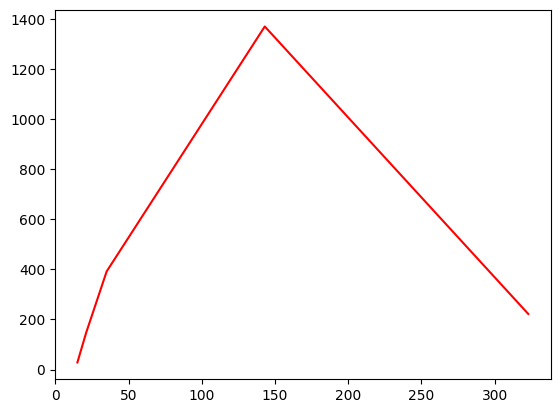

In [13]:
t_shor_naive = []
t_shor_opti = []

primes = [15, 21, 35, 143, 323]

# for N in primes:
#     stmt = lambda N=N: Shor(N, True)

#     times = timeit.repeat(stmt, repeat=1, number=1)
#     # best_per_call = np.mean(np.array(times)) / 1
#     best_per_call = np.mean(np.array(times)) * 1000
#     print(best_per_call)

#     t_shor_naive.append(best_per_call)

for N in primes:
    stmt = lambda N=N: Shor(N, False)

    # times = timeit.repeat(stmt, repeat=5, number=10)
    times = timeit.repeat(stmt, repeat=1, number=2)
    # best_per_call = np.mean(np.array(times)) / 1
    best_per_call = np.mean(np.array(times)) * 1000 / 2
    print(best_per_call)

    t_shor_opti.append(best_per_call)

# plt.plot(primes, t_shor_naive)
plt.plot(primes, t_shor_opti, c='red')
# plt.plot(primes, np.array(primes) ** 3, c='blue')
# plt.plot(range(0, 400), t_shor_opti)
# plt.xscale("log", base = 2)
plt.show()

37.858700001379475
34.07180000067456
31.560700001136865
27.109700000437442
30.62599999975646
28.047100000549108
36.00220000225818
33.34709999762708
34.49850000470178
29.98430000297958


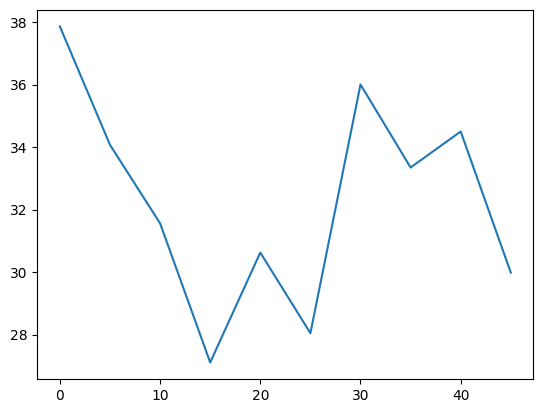

In [25]:
t_opt = []

max = 50

for i in range(0, max, 5):
    stmt = lambda i=i: ApplyUGateOptimized(4, 15, i)
    
    times = timeit.repeat(stmt, repeat=1, number=1)
    # best_per_call = np.mean(np.array(times)) / 1
    best_per_call = min(times) * 1000
    print(best_per_call)

    t_opt.append(best_per_call)

plt.plot(range(0, max, 5), t_opt)

0.026863606770833336


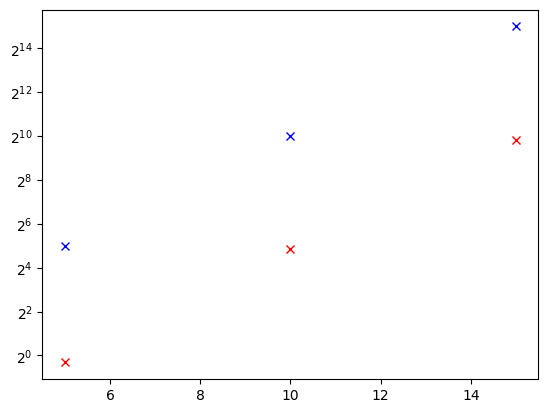

In [3]:

p = [5, 10, 15]
t = [0.8, 28.8, 15*60]
t2 = [2**5, 2**10, 2**15]

plt.yscale('log', base = 2)

alphas = np.array(t) / np.array(t2)
print(alphas.mean())

plt.plot(p, t, "x", c='red')
plt.plot(p, t2, "x", c='blue')
plt.show()

In [ ]:
# N = [15, 21, 35]
N = [15]
p = [5, 10, 15]

g = 4

fix, ax = plt.subplots()

for power in p:

    times_for_this_power = []

    for modulo in N:
        stmt = lambda: ApplyUGateNaive(g, modulo, power)
        
        times = timeit.repeat(stmt, repeat=1, number=1)
        # best_per_call = np.mean(np.array(times)) / 1
        best_per_call = min(times) * 1000
        
        times_for_this_power.append(best_per_call)

        print(f"[N = {modulo} ; p = {power}] {best_per_call:.6f} ms par appel")

    ax.plot(N, times_for_this_power, marker='o', label=f"Power p = {power}")

ax.set_title(f"Temps d'exécution de ApplyUGateOptimized (Générateur g={g})")
ax.set_xlabel("Taille du Modulo (N)")
ax.set_ylabel("Temps moyen par appel (secondes)")
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend() # Affiche la légende (Power p = 5, etc.)

NameError: name 'plt' is not defined

Version naïve : multiplication modulaire lancée 2^p fois

Version optimisée : calcul de a^2^p en O(log p) opérations classiques + multiplication modulaire lancée 1 fois

In [10]:
N = 15
p = 15

stmt_opt = lambda: ApplyUGateOptimized(g, N, p)
t_opt = timeit.repeat(stmt_opt, repeat=5, number=10)
best_opt = min(t_opt) / 10
print(best_opt)

print(np.log2(p))

0.02656637000000046
3.9068905956085187


In [ ]:
N_values = [15, 21, 35]
p_values = [5, 10, 15]

g = 4

times_naive = []
times_optimized = []

fig, ax = plt.subplots()

for power in p_values:
    # print("#1")
    # --- Benchmark version naïve ---
    # stmt_naive = lambda: ApplyUGateNaive(g, N_values[0], power)
    # # Attention, si p est très grand, la version naïve sera trop longue, tu devras peut-être réduire 'number'
    # t_naive = timeit.repeat(stmt_naive, repeat=1, number=1)
    # best_naive = min(t_naive) / 10
    # times_naive.append(best_naive * 1000)
    
    # print("#2")

    # --- Benchmark version optimisée ---
    stmt_opt = lambda: ApplyUGateOptimized(g, N_values[0], power)
    t_opt = timeit.repeat(stmt_opt, repeat=5, number=10)
    best_opt = min(t_opt) / 10
    times_optimized.append(best_opt * 1000)
    
    print("#3")
    # print(f"p={power:2d} | Naive: {best_naive:.6f}s | Opt: {best_opt:.6f}s")
    print(f"p={power:2d} | Opt: {best_opt:.6f}ms")

print(times_optimized)

# --- Tracé des courbes ---
# Ligne pour la version naïve (qui devrait grimper très vite)
# ax.plot(p_values, times_naive, marker='o', color='red', label="Naïve O(2^p)")

# Ligne pour la version optimisée (qui devrait rester très basse et plate)
ax.plot(p_values, times_optimized, marker='s', color='green', label="Optimisée O(log p)")
ax.plot(range(15), range(15))

# --- Mise en forme ---
ax.set_title(f"Comparaison d'exécution (Modulo {N_values[0]}, Générateur {g})")
ax.set_xlabel("Puissance (p)")
ax.set_ylabel("Temps moyen par appel (secondes)")
plt.yscale('log')
# Échelle logarithmique sur l'axe Y : crucial pour comparer exponentielle et log/poly !
# ax.set_yscale('log') 

ax.grid(True, which="both", linestyle='--', alpha=0.5)
ax.legend()

plt.show()

=== Version naïve ===
  p= 1  (   2 appels quantiques)  →  7.2 ms
  p= 2  (   4 appels quantiques)  →  16.6 ms
  p= 3  (   8 appels quantiques)  →  29.3 ms
  p= 4  (  16 appels quantiques)  →  55.5 ms
  p= 5  (  32 appels quantiques)  →  124.3 ms
  p= 6  (  64 appels quantiques)  →  244.6 ms
  p= 7  ( 128 appels quantiques)  →  462.6 ms
  p= 8  ( 256 appels quantiques)  →  914.9 ms

=== Version optimisée ===
  p= 1  →  3.492 ms
  p= 2  →  3.673 ms
  p= 3  →  3.394 ms
  p= 4  →  3.499 ms
  p= 5  →  3.382 ms
  p= 6  →  3.754 ms
  p= 7  →  3.394 ms
  p= 8  →  3.556 ms
  p= 9  →  3.426 ms
  p=10  →  3.501 ms
  p=11  →  3.560 ms
  p=12  →  3.370 ms
  p=13  →  3.431 ms
  p=14  →  3.558 ms
  p=15  →  3.464 ms
  p=16  →  3.451 ms
  p=17  →  3.339 ms
  p=18  →  3.485 ms
  p=19  →  3.652 ms
  p=20  →  3.388 ms

=== Version optimisée ===
  p= 1  →  5.134 ms
  p= 2  →  4.870 ms
  p= 3  →  5.319 ms
  p= 4  →  4.920 ms
  p= 5  →  4.981 ms
  p= 6  →  5.391 ms
  p= 7  →  5.363 ms
  p= 8  →  4.864 ms
 

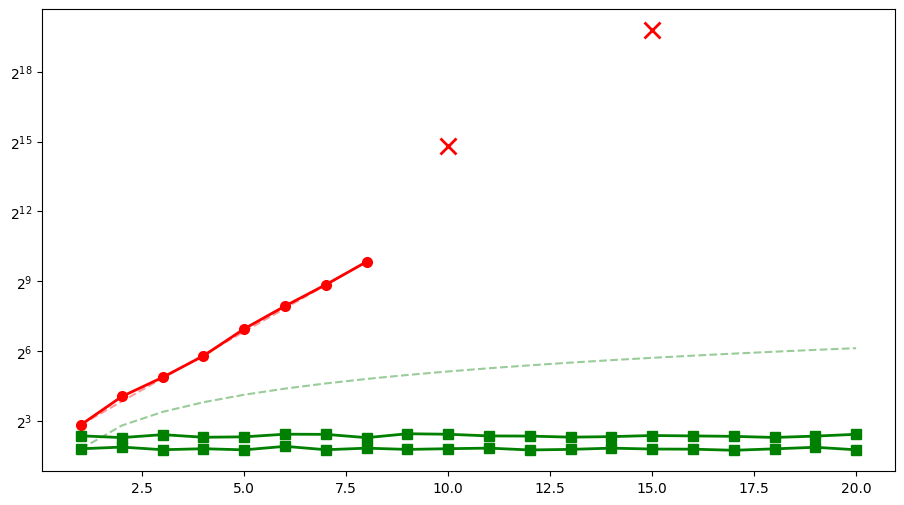

In [12]:
import qsharp
qsharp.init(project_root='../')
from qsharp.code.PhaseEstimation import ApplyUGateNaive, ApplyUGateOptimized
import numpy as np
import timeit
import matplotlib.pyplot as plt

g, N = 4, 15

# Naïve : limiter à p≤8 (2^8=256 appels × ~27ms ≈ 7s par point — supportable)
p_naive = [1, 2, 3, 4, 5, 6, 7, 8]
times_naive = []

print("=== Version naïve ===")
for p in p_naive:
    stmt = lambda p=p: ApplyUGateNaive(g, N, p, int(np.ceil(np.log2(N))))
    t = timeit.repeat(stmt, repeat=1, number=1)
    ms = min(t) * 1000
    times_naive.append(ms)
    print(f"  p={p:2d}  ({2**p:4d} appels quantiques)  →  {ms:.1f} ms")

# Optimisée : peut aller jusqu'à p=20+ (1 seule porte + O(p) classique)
p_opt = list(range(1, 21))
times_opt = []

print("\n=== Version optimisée ===")
for p in p_opt:
    stmt = lambda p=p: ApplyUGateOptimized(g, N, p, int(np.ceil(np.log2(N))))
    t = timeit.repeat(stmt, repeat=3, number=5)
    ms = min(t) / 5 * 1000
    times_opt.append(ms)
    print(f"  p={p:2d}  →  {ms:.3f} ms")

# Optimisée 2 : peut aller jusqu'à p=20+ (1 seule porte + O(p) classique)
p_opt = list(range(1, 21))
times_opt2 = []

print("\n=== Version optimisée ===")
for p in p_opt:
    stmt = lambda p=p: ApplyUGateOptimized(g, 21, p, int(np.ceil(np.log2(21))))
    t = timeit.repeat(stmt, repeat=3, number=5)
    ms = min(t) / 5 * 1000
    times_opt2.append(ms)
    print(f"  p={p:2d}  →  {ms:.3f} ms")


# Courbes théoriques normalisées au 1er point mesuré
c_exp = times_naive[0] / (2 ** p_naive[0])
c_lin = times_opt[0]   / p_opt[0]
theory_exp = [c_exp * (2 ** p) for p in p_naive]
theory_lin = [c_lin * p        for p in p_opt]

# On ajoute les mesures déjà collectées manuellement (p=10, p=15)
p_naive_known     = [10,    15]
times_naive_known = [28800, 900_000]  # ms

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(p_naive,       times_naive,       'ro-', lw=2, ms=7,  label="Naïve — mesuré  O(2^p) portes Q#")
ax.plot(p_naive_known, times_naive_known, 'rx',  ms=12, mew=2, label="Naïve — mesures p=10, 15")
ax.plot(p_opt,         times_opt,         'gs-', lw=2, ms=7,  label="Optimisée — mesuré  O(p) classique + 1 porte")
ax.plot(p_opt,         times_opt2,         'gs-', lw=2, ms=7,  label="Optimisée 2 — mesuré  O(p) classique + 1 porte")
ax.plot(p_naive,       theory_exp,        'r--', alpha=0.4,    label="Théorique C·2^p")
ax.plot(p_opt,         theory_lin,        'g--', alpha=0.4,    label="Théorique C·p")

plt.yscale("log", base=2)


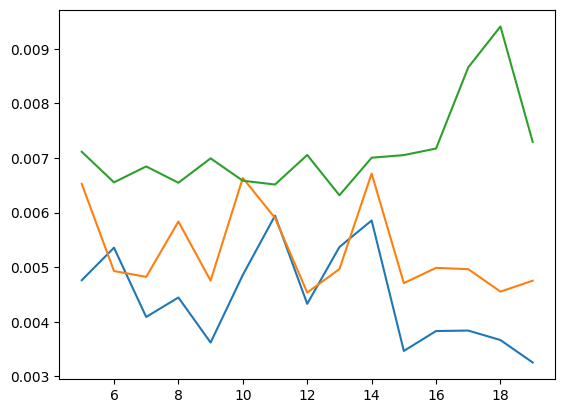

In [40]:
import time

g = 4

for N in [15, 21, 35]:
    times = []
    for p in range(5, 20):
        start = time.time()
        ApplyUGateOptimized(g, N, p, int(np.ceil(np.log2(N))))
        end = time.time()
        times.append(end - start)
    plt.plot(range(5, 20), times)

plt.show()

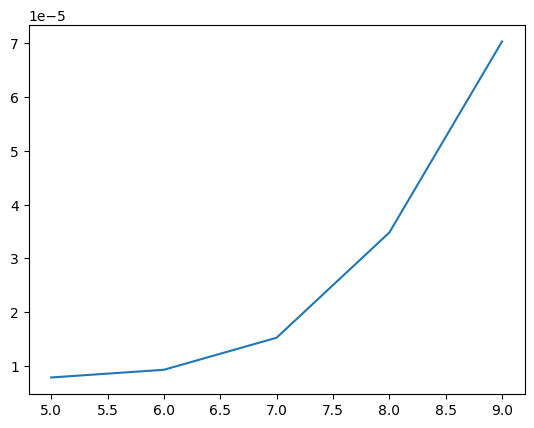

In [52]:
a = 0

times = []
for p in range(5, 10):
    start = time.time()
    for i in range(2**p):
        a += 1
    end = time.time()
    times.append(end - start)

plt.plot(range(5, 10), times)
# plt.yscale("log", base = 2)
plt.show()

N=15 p= 5 | naïf=   122.5 ms | opt=5.336 ms
N=15 p=10 | naïf=  4175.8 ms | opt=5.045 ms
N=15 p=15 | naïf=131222.1 ms | opt=3.526 ms
N=21 p= 5 | naïf=   179.1 ms | opt=6.852 ms
N=21 p=10 | naïf=  5620.9 ms | opt=5.874 ms
N=21 p=15 | naïf=187892.6 ms | opt=5.109 ms
N=35 p= 5 | naïf=   255.2 ms | opt=8.407 ms
N=35 p=10 | naïf=  7103.4 ms | opt=5.578 ms
N=35 p=15 | naïf=256293.8 ms | opt=8.708 ms


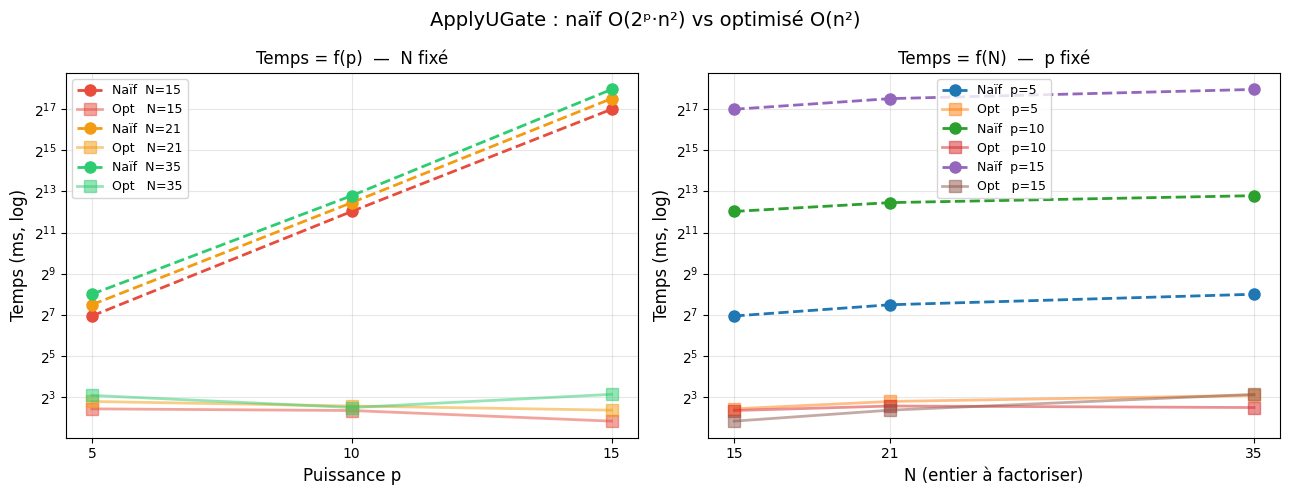

In [ ]:
import qsharp
qsharp.init(project_root='../')
from qsharp.code.PhaseEstimation import ApplyUGateNaive, ApplyUGateOptimized
import numpy as np
import timeit

g = 4
N_values = [15, 21, 35]
p_values = [5, 10, 15]

def measure(fn, repeat=1, number=1):
    t = timeit.repeat(fn, repeat=repeat, number=number)
    return min(t) / number * 1000  # ms

results = {}  # (N, p) -> (t_naive, t_opt)

for N in N_values:
    n = int(np.ceil(np.log2(N)))
    for p in p_values:
        t_naive = measure(lambda N=N, p=p, n=n: ApplyUGateNaive(g, N, p, n))
        t_opt   = measure(lambda N=N, p=p, n=n: ApplyUGateOptimized(g, N, p, n))
        results[(N, p)] = (t_naive, t_opt)
        print(f"N={N:2d} p={p:2d} | naïf={t_naive:8.1f} ms | opt={t_opt:.3f} ms")


import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("ApplyUGate : naïf O(2ᵖ·n²) vs optimisé O(n²)", fontsize=14)

colors = {15: "#E74C3C", 21: "#F39C12", 35: "#2ECC71"}

ax = axes[0]
for N in N_values:
    t_n = [results[(N, p)][0] for p in p_values]
    t_o = [results[(N, p)][1] for p in p_values]
    ax.plot(p_values, t_n, 'o--', color=colors[N], lw=2, ms=8, label=f"Naïf  N={N}")
    ax.plot(p_values, t_o, 's-',  color=colors[N], lw=2, ms=8, alpha=0.5, label=f"Opt   N={N}")

ax.set_yscale("log", base=2)
ax.set_xlabel("Puissance p", fontsize=12)
ax.set_ylabel("Temps (ms, log)", fontsize=12)
ax.set_title("Temps = f(p)  —  N fixé", fontsize=12)
ax.set_xticks(p_values)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)


ax = axes[1]
for p in p_values:
    t_n = [results[(N, p)][0] for N in N_values]
    t_o = [results[(N, p)][1] for N in N_values]
    ax.plot(N_values, t_n, 'o--', lw=2, ms=8, label=f"Naïf  p={p}")
    ax.plot(N_values, t_o, 's-',  lw=2, ms=8, alpha=0.5, label=f"Opt   p={p}")

ax.set_yscale("log", base=2)
ax.set_xlabel("N (entier à factoriser)", fontsize=12)
ax.set_ylabel("Temps (ms, log)", fontsize=12)
ax.set_title("Temps = f(N)  —  p fixé", fontsize=12)
ax.set_xticks(N_values)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("benchmark_applyugate.png", dpi=150)
plt.show()

N=15 p= 5 | naïf=     0.0 ms | opt=3.218 ms
N=15 p=10 | naïf=     0.0 ms | opt=3.305 ms
N=15 p=15 | naïf=     0.0 ms | opt=3.425 ms
N=15 p=20 | naïf=     0.0 ms | opt=3.136 ms
N=15 p=25 | naïf=     0.0 ms | opt=3.662 ms
N=15 p=30 | naïf=     0.0 ms | opt=3.486 ms
N=15 p=35 | naïf=     0.0 ms | opt=3.356 ms
N=15 p=40 | naïf=     0.0 ms | opt=3.441 ms
N=15 p=45 | naïf=     0.0 ms | opt=3.511 ms
N=15 p=50 | naïf=     0.0 ms | opt=3.243 ms
N=15 p=55 | naïf=     0.0 ms | opt=3.222 ms
N=21 p= 5 | naïf=     0.0 ms | opt=5.143 ms
N=21 p=10 | naïf=     0.0 ms | opt=4.674 ms
N=21 p=15 | naïf=     0.0 ms | opt=5.037 ms
N=21 p=20 | naïf=     0.0 ms | opt=5.004 ms
N=21 p=25 | naïf=     0.0 ms | opt=4.897 ms
N=21 p=30 | naïf=     0.0 ms | opt=5.306 ms
N=21 p=35 | naïf=     0.0 ms | opt=5.788 ms
N=21 p=40 | naïf=     0.0 ms | opt=4.883 ms
N=21 p=45 | naïf=     0.0 ms | opt=5.097 ms
N=21 p=50 | naïf=     0.0 ms | opt=4.916 ms
N=21 p=55 | naïf=     0.0 ms | opt=5.196 ms
N=35 p= 5 | naïf=     0.0 ms | o

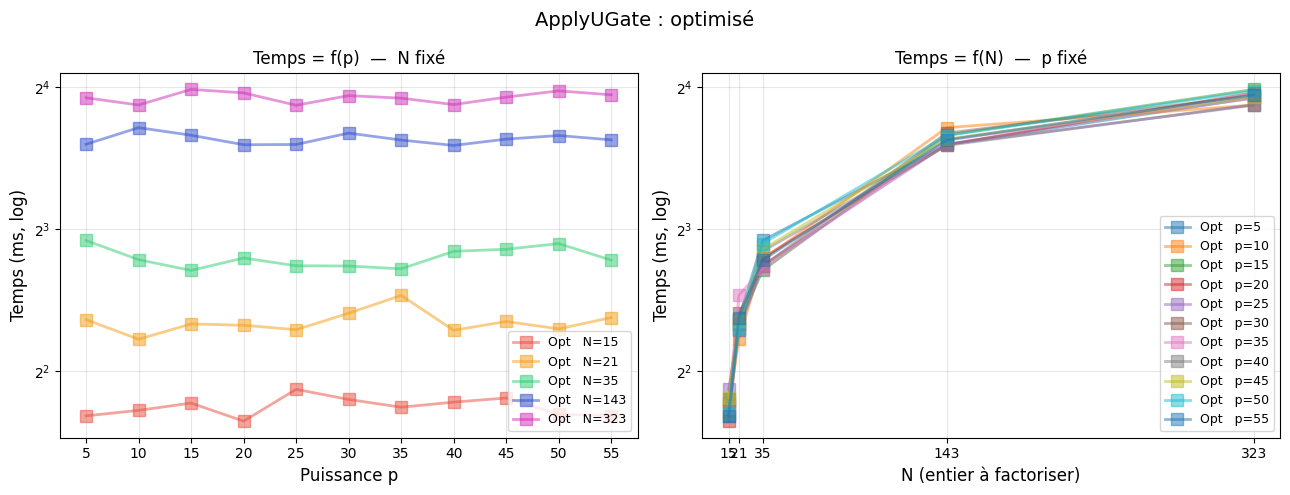

In [20]:
import qsharp
qsharp.init(project_root='../')
from qsharp.code.PhaseEstimation import ApplyUGateNaive, ApplyUGateOptimized
import numpy as np
import timeit

g = 4
N_values = [15, 21, 35, 143, 323]
# p_values = [5, 10, 15]
p_values = range(5, 60, 5)

def measure(fn, repeat=3, number=3):
    t = timeit.repeat(fn, repeat=repeat, number=number)
    return min(t) / number * 1000  # ms

results = {}  # (N, p) -> (t_naive, t_opt)

for N in N_values:
    n = int(np.ceil(np.log2(N)))
    for p in p_values:
        t_naive = 0
        # t_naive = measure(lambda N=N, p=p, n=n: ApplyUGateNaive(g, N, p, n))
        t_opt   = measure(lambda N=N, p=p, n=n: ApplyUGateOptimized(g, N, p, n))
        results[(N, p)] = (t_naive, t_opt)
        print(f"N={N:2d} p={p:2d} | naïf={t_naive:8.1f} ms | opt={t_opt:.3f} ms")


import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("ApplyUGate : optimisé", fontsize=14)

colors = {15: "#E74C3C", 21: "#F39C12", 35: "#2ECC71", 143: "#2E4BCC", 323: "#CC2EB7"}

ax = axes[0]
for N in N_values:
    t_n = [results[(N, p)][0] for p in p_values]
    t_o = [results[(N, p)][1] for p in p_values]
    # ax.plot(p_values, t_n, 'o--', color=colors[N], lw=2, ms=8, label=f"Naïf  N={N}")
    ax.plot(p_values, t_o, 's-',  color=colors[N], lw=2, ms=8, alpha=0.5, label=f"Opt   N={N}")

ax.set_yscale("log", base=2)
ax.set_xlabel("Puissance p", fontsize=12)
ax.set_ylabel("Temps (ms, log)", fontsize=12)
ax.set_title("Temps = f(p)  —  N fixé", fontsize=12)
ax.set_xticks(p_values)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)


ax = axes[1]
for p in p_values:
    t_n = [results[(N, p)][0] for N in N_values]
    t_o = [results[(N, p)][1] for N in N_values]
    # ax.plot(N_values, t_n, 'o--', lw=2, ms=8, label=f"Naïf  p={p}")
    ax.plot(N_values, t_o, 's-',  lw=2, ms=8, alpha=0.5, label=f"Opt   p={p}")

# ax.plot(range(1, 143), np.log2(np.array(range(1,143))))

ax.set_yscale("log", base=2)
ax.set_xlabel("N (entier à factoriser)", fontsize=12)
ax.set_ylabel("Temps (ms, log)", fontsize=12)
ax.set_title("Temps = f(N)  —  p fixé", fontsize=12)
ax.set_xticks(N_values)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("benchmark_applyugate.png", dpi=150)
plt.show()

In [ ]:
import qsharp
qsharp.init(project_root='../')
from qsharp.code.PhaseEstimation import ApplyUGateNaive, ApplyUGateOptimized, ExpMod
import numpy as np
import timeit

g = 4
N_values = [15]
# p_values = [5, 10, 15]
p_values = range(5, 1000, 5)

def measure(fn, repeat=3, number=3):
    t = timeit.repeat(fn, repeat=repeat, number=number)
    return min(t) / number * 1000  # ms

results = {}  # (N, p) -> (t_naive, t_opt)

for N in N_values:
    n = int(np.ceil(np.log2(N)))
    for p in p_values:
        t_naive = 0
        # t_naive = measure(lambda N=N, p=p, n=n: ApplyUGateNaive(g, N, p, n))
        t_opt   = measure(lambda N=N, p=p, n=n: ExpMod(g, p, N))
        results[(N, p)] = (t_naive, t_opt)
        print(f"N={N:2d} p={p:2d} | naïf={t_naive:8.1f} ms | opt={t_opt:.3f} ms")


import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("ApplyUGate : optimisé", fontsize=14)

colors = {15: "#E74C3C", 21: "#F39C12", 35: "#2ECC71", 143: "#2E4BCC", 323: "#CC2EB7"}

ax = axes[0]
for N in N_values:
    t_n = [results[(N, p)][0] for p in p_values]
    t_o = [results[(N, p)][1] for p in p_values]
    # ax.plot(p_values, t_n, 'o--', color=colors[N], lw=2, ms=8, label=f"Naïf  N={N}")
    ax.plot(p_values, t_o, 's-',  color=colors[N], lw=2, ms=8, alpha=0.5, label=f"Opt   N={N}")

# ax.set_yscale("log", base=2)
ax.set_xlabel("Puissance p", fontsize=12)
ax.set_ylabel("Temps (ms, log)", fontsize=12)
ax.set_title("Temps = f(p)  —  N fixé", fontsize=12)
# ax.set_xticks(p_values)
# ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)


ax = axes[1]
for p in p_values:
    t_n = [results[(N, p)][0] for N in N_values]
    t_o = [results[(N, p)][1] for N in N_values]
    # ax.plot(N_values, t_n, 'o--', lw=2, ms=8, label=f"Naïf  p={p}")
    ax.plot(N_values, t_o, 's-',  lw=2, ms=8, alpha=0.5, label=f"Opt   p={p}")

# ax.plot(range(1, 143), np.log2(np.array(range(1,143))))

ax.set_yscale("log", base=2)
ax.set_xlabel("N (entier à factoriser)", fontsize=12)
ax.set_ylabel("Temps (ms, log)", fontsize=12)
ax.set_title("Temps = f(N)  —  p fixé", fontsize=12)
# ax.set_xticks(N_values)
# ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
# plt.savefig("benchmark_applyugate.png", dpi=150)
plt.show()

N=15 p= 5 | naïf=     0.0 ms | opt=0.015 ms
N=15 p=10 | naïf=     0.0 ms | opt=0.016 ms
N=15 p=15 | naïf=     0.0 ms | opt=0.019 ms
N=15 p=20 | naïf=     0.0 ms | opt=0.022 ms
N=15 p=25 | naïf=     0.0 ms | opt=0.025 ms
N=15 p=30 | naïf=     0.0 ms | opt=0.027 ms
N=15 p=35 | naïf=     0.0 ms | opt=0.028 ms
N=15 p=40 | naïf=     0.0 ms | opt=0.031 ms
N=15 p=45 | naïf=     0.0 ms | opt=0.034 ms
N=15 p=50 | naïf=     0.0 ms | opt=0.036 ms
N=15 p=55 | naïf=     0.0 ms | opt=0.039 ms
N=15 p=60 | naïf=     0.0 ms | opt=0.041 ms


QSharpError: Error: integer too large for operation
Call stack:
    at PhaseEstimation.ExpMod in ..\src\PhaseEstimation.qs:9:25
Qsc.Eval.IntTooLarge

  x runtime error
  `-> integer too large for operation
    ,-[..\src\PhaseEstimation.qs:9:31]
  8 | {
  9 |     ExpModI(generator, (1 <<< power), modulo);
    :                               ^^|^^
    :                                 `-- this value is too large
 10 |     return 0;
    `----


: 